# **Data Visualisation and Communication - CA2**

Additional Variable Information about the dataset

**InvoiceNo**: Invoice number. Nominal, a 6-digit integral number uniquely assigned to each transaction. If this code starts with letter 'c', it indicates a cancellation.

**StockCode**: Product (item) code. Nominal, a 5-digit integral number uniquely assigned to each distinct product.

**Description**: Product (item) name. Nominal.

**Quantity**: The quantities of each product (item) per transaction. Numeric.

**InvoiceDate**: Invoice Date and time. Numeric, the day and time when each transaction was generated.

**UnitPrice**: Unit price. Numeric, Product price per unit in sterling.

**CustomerID**: Customer number. Nominal, a 5-digit integral number uniquely assigned to each customer.

**Country** Country name. Nominal, the name of the country where each customer resides. 


## **Index**

### **1. LIBRARIES**

In [1]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### **2. LOADING THE DATA**

In [2]:
## Changing the format file to a CSV
## Note: I had to replace the blank space between the words "Online" and "Retail" and add a "_" to make this code work.

FOLDER = r'C:\Users\felip\Documents\CA2-DataVisComms\DataVisComms-CA2' # This is the folder where the files will be.
XLSX_PATH = os.path.join(FOLDER, "Online_Retail.xlsx")
CSV_PATH = os.path.join(FOLDER, "Online_Retail.csv")

# Only convert if the CSV is not there yet
if not os.path.exists(CSV_PATH):
    print("( (!) CSV not found, converting the Excel file (this can take a few minutes)...")
    pd.read_excel(XLSX_PATH).to_csv(CSV_PATH, index=False)
    print("Done!")
else:
    print("======> CSV already exists, nothing to convert <======")

======> CSV already exists, nothing to convert <======


In [3]:
# Checking the structure of the dataset

df = pd.read_csv(CSV_PATH, low_memory=False)

print("Rows:", df.shape[0], "| columns:", df.shape[1]) # printing how meny columns and rows.
print("\n")
df.head() # Checking the dataset
df.info() #  Checking the data type, columns and entries

Rows: 541909 | columns: 8


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


### **3. HANDLING MISSING VALUES**

Before analysing any data, I have to ask a simple question: does every row represent what I think it represents? The answer is easy: no, because of the following information provided by the dataset's author.

Cancelled invoices that start with C are returns or cancellations, not sales.
Quantity of zero or less, a customer can't buy zero or minus six items.
Unitprice of zero or less, a sale with no price, or a negative one, has no sales value.
Country marked Unspecified, meaning not a real country or data loss.

The principle behind all four is that the quality of the conclusion can't be better than the quality of the data.

In [4]:
# Preparing the data types per columns.
df["InvoiceNo"]   = df["InvoiceNo"].astype(str).str.strip()
df["StockCode"]   = df["StockCode"].astype(str).str.strip()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["CustomerID"]  = df["CustomerID"].astype("Int64").astype("string")
df["Description"] = df["Description"].str.strip()
df["Country"]     = df["Country"].str.strip()

raw_rows = len(df)
print("Raw rows:", raw_rows) # Total raw rows

Raw rows: 541909


In [5]:
# 1. Checking missing values
miss = df.isnull().sum()
print(pd.DataFrame({"missing": miss, "pct": (miss / len(df) * 100).round(2)}))

             missing    pct
InvoiceNo          0   0.00
StockCode          0   0.00
Description     1454   0.27
Quantity           0   0.00
InvoiceDate        0   0.00
UnitPrice          0   0.00
CustomerID    135080  24.93
Country            0   0.00


In [6]:
## Are the missing Descriptions non-sales?
no_desc = df[df["Description"].isnull()]
print("Missing description with price == 0:", (no_desc["UnitPrice"] == 0).mean())
print("Missing description with no customer:", no_desc["CustomerID"].isnull().mean())

Missing description with price == 0: 1.0
Missing description with no customer: 1.0


In [7]:
# Handling missing values
# Filling from the StockCode if possible.
desc_map = (df.dropna(subset=["Description"])
              .groupby("StockCode")["Description"]
              .agg(lambda s: s.mode().iloc[0]))
df["Description"] = df["Description"].fillna(df["StockCode"].map(desc_map))
print("Description still missing:", df["Description"].isnull().sum())

# CustomerID: do NOT impute, flag instead
df["is_guest"] = df["CustomerID"].isnull()
print("Guest rows:", df["is_guest"].sum())

# The 112 rows that can't be filled have a price of 0.

Description still missing: 112
Guest rows: 135080


### **4. INVALID RECORDS**

In [8]:
# 4. Flag invalid values.
# Based on the information provided by the author, it is important to flag some columns to keep the dataset
# as clean as possible.

# Explicit list of non-product codes, identified from the audit output.
NON_PRODUCT = r"^(POST|DOT|M|C2|D|S|BANK CHARGES|AMAZONFEE|CRUK|PADS|B|gift_0001_\d+)$"

is_cancel  = df["InvoiceNo"].str.upper().str.startswith("C") # All the invoices with C
neg_qty    = df["Quantity"] <= 0 # ALl the negative quantities
bad_price  = df["UnitPrice"] <= 0 # all the negative prices
non_prod   = df["StockCode"].str.match(NON_PRODUCT, case=False)
dup        = df.duplicated(keep="first") # The exact duplicates 
unspec     = df["Country"].eq("Unspecified") # The unspecified countries

print("Cancelled (C):", is_cancel.sum())
print("Quantity <= 0:", neg_qty.sum(), "| < 0:", (df["Quantity"] < 0).sum(), "| == 0:", (df["Quantity"] == 0).sum())
print("UnitPrice <= 0:", bad_price.sum(), "| < 0:", (df["UnitPrice"] < 0).sum(), "| == 0:", (df["UnitPrice"] == 0).sum())
print("Non-product StockCodes:", non_prod.sum())
print("Exact duplicates:", dup.sum())
print("Country Unspecified:", unspec.sum())
print("C rows with positive qty (should be 0):", (is_cancel & (df['Quantity'] > 0)).sum())
print("Negative qty, not cancelled:", (neg_qty & ~is_cancel).sum())
print("\n")
# See which StockCodes were classed as non-products
print(df[non_prod].groupby("StockCode")["Description"]
        .agg(rows="size", example="first").sort_values("rows", ascending=False).head(20))


Cancelled (C): 9288
Quantity <= 0: 10624 | < 0: 10624 | == 0: 0
UnitPrice <= 0: 2517 | < 0: 2 | == 0: 2515
Non-product StockCodes: 2950
Exact duplicates: 5268
Country Unspecified: 446
C rows with positive qty (should be 0): 0
Negative qty, not cancelled: 1336


              rows                             example
StockCode                                             
POST          1256                             POSTAGE
DOT            710                      DOTCOM POSTAGE
M              571                              Manual
C2             144                            CARRIAGE
D               77                            Discount
S               63                             SAMPLES
BANK CHARGES    37                        Bank Charges
AMAZONFEE       34                          AMAZON FEE
CRUK            16                     CRUK Commission
gift_0001_20    10  Dotcomgiftshop Gift Voucher £20.00
gift_0001_10     9  Dotcomgiftshop Gift Voucher £10.00
gift_0001_30     8  Dot

In [9]:
# Handling invalid values. (using the last audit)
steps = [
    ("cancelled invoices (C)",   is_cancel),
    ("negative/zero quantity",   neg_qty),
    ("zero/negative price",      bad_price),
    ("non-product stock codes",  non_prod),
    ("exact duplicates",         dup),
]

remaining = pd.Series(True, index=df.index)
audit = [("raw rows", raw_rows)]
for name, mask in steps:
    hit = remaining & mask
    audit.append((f"removed: {name}", int(hit.sum())))
    remaining &= ~mask
audit.append(("clean rows", int(remaining.sum())))
print(pd.DataFrame(audit, columns=["step", "rows"]))

cancellations = df[is_cancel].copy()      # keep for return analysis
clean = df[remaining].copy()

clean["Revenue"] = clean["Quantity"] * clean["UnitPrice"]
clean["Country"] = clean["Country"].replace("Unspecified", "Unknown")


                               step    rows
0                          raw rows  541909
1   removed: cancelled invoices (C)    9288
2   removed: negative/zero quantity    1336
3      removed: zero/negative price    1181
4  removed: non-product stock codes    2346
5         removed: exact duplicates    5221
6                        clean rows  522537


In [10]:
# Checking the data again.

miss = clean.isnull().sum()
print(pd.DataFrame({"missing": miss, "pct": (miss / len(clean) * 100).round(2)}))
print("Rows:", len(clean))
print("Quantity min:", clean["Quantity"].min(), "| UnitPrice min:", clean["UnitPrice"].min())
print("Cancelled left:", clean["InvoiceNo"].str.upper().str.startswith("C").sum())   # expect 0
print("\n")
print("Duplicates Before:", df.duplicated().sum())
print("Duplicates left:", clean.duplicated().sum())

             missing    pct
InvoiceNo          0   0.00
StockCode          0   0.00
Description        0   0.00
Quantity           0   0.00
InvoiceDate        0   0.00
UnitPrice          0   0.00
CustomerID    131387  25.14
Country            0   0.00
is_guest           0   0.00
Revenue            0   0.00
Rows: 522537
Quantity min: 1 | UnitPrice min: 0.04
Cancelled left: 0


Duplicates Before: 5268
Duplicates left: 0


### **5. DUPLICATES**

In [11]:
# Summary of the new dataset "clean".
clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,is_guest,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,False,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,False,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,20.34


### **6. OUTLIERS**

In [12]:
# Checking the min, max, and the 99th percentile on clean.
print(clean[["Quantity", "UnitPrice", "Revenue"]].describe(percentiles=[.99]).round(2))

# The ouput shows the smalles, largest and typical values, and because the max is far above the 99th percentile,
# there are extreme values.

        Quantity  UnitPrice    Revenue
count  522537.00  522537.00  522537.00
mean       10.64       3.27      19.61
std       156.59       4.39     269.94
min         1.00       0.04       0.06
50%         4.00       2.08       9.90
99%       100.00      16.63     179.00
max     80995.00     649.50  168469.60


In [13]:
# Flagging outliers using the 3xIQR rule, and counting them.

for col in ["Quantity", "UnitPrice", "Revenue"]:
    q1, q3 = clean[col].quantile([.25, .75])
    clean[col + "_outlier"] = clean[col] > q3 + 3 * (q3 - q1)
    print(col, "outliers:", clean[col + "_outlier"].sum())

# This Flag category is an outlier that it is more than 3xIQR above the third quartile (Q3), and it add
# a True or False column, and no rows are deleted.

Quantity outliers: 19152
UnitPrice outliers: 10126
Revenue outliers: 26237


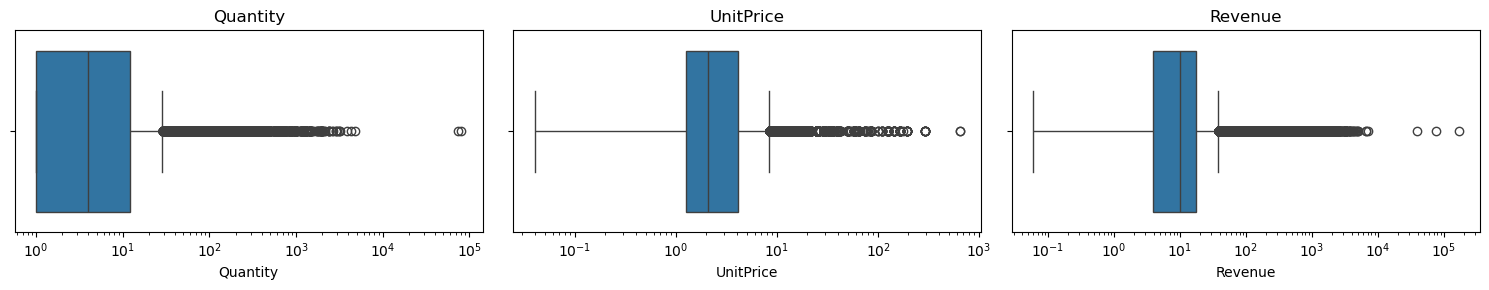

In [14]:
# Boxplots (log scale because the data is very skewed)
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, col in zip(axes, ["Quantity", "UnitPrice", "Revenue"]):
    sns.boxplot(x=clean[col], ax=ax)
    ax.set_xscale("log")
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [15]:
# Handling the extreme rows.
cols = ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "Revenue", "CustomerID"]
for col in ["Quantity", "UnitPrice", "Revenue"]:
    print(clean.nlargest(5, col)[cols], "\n")

       InvoiceNo StockCode                        Description  Quantity  \
540421    581483     23843        PAPER CRAFT , LITTLE BIRDIE     80995   
61619     541431     23166     MEDIUM CERAMIC TOP STORAGE JAR     74215   
421632    573008     84077  WORLD WAR 2 GLIDERS ASSTD DESIGNS      4800   
206121    554868     22197               SMALL POPCORN HOLDER      4300   
97432     544612     22053              EMPIRE DESIGN ROSETTE      3906   

        UnitPrice    Revenue CustomerID  
540421       2.08  168469.60      16446  
61619        1.04   77183.60      12346  
421632       0.21    1008.00      12901  
206121       0.72    3096.00      13135  
97432        0.82    3202.92      18087   

       InvoiceNo StockCode                     Description  Quantity  \
222680    556444     22502  PICNIC BASKET WICKER 60 PIECES        60   
222682    556446     22502  PICNIC BASKET WICKER 60 PIECES         1   
4989      536835     22655     VINTAGE RED KITCHEN CABINET         1   
32484  

In [ ]:
# Handling the outliers


### **7. LIMITATIONS**

Some limitations are that the data covers only about 12 months, so seasonality can't be separated from trend, december is not complete.
About 25% of rows have no CustomerID, so these rows were kept and flagged with is_guest for future analysis. 
The cancellations do not have any references to the original invoice number or ID, so the return can't be matched to sales.
446 rows have Country "Unspecified", so they are excluded from country comparison in future analysis.